In [1]:
# my jupyter notebook on my computer does not work so I used google drive, change these imports based off of your own computer
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from itertools import combinations
from scipy.spatial.distance import pdist, squareform
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
# Getting Density Data
density_data = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/density_data_cleaned.csv')
print('Converted Density Data to density_data dataframe')

# Getting Rooms With Kitchens Data
rooms_with_kitchens = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/rooms_with_kitchens_cleaned.csv')
print('Converted Rooms With Kitchens Data to density_data dataframe')

# Getting Building List Data
building_list = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/building_list_cleaned.csv')
print('Converted Building List Data to building_list dataframe')

# Getting High Volume Event Spaces Data
high_volume_event_spaces = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/high_volume_event_spaces_cleaned.csv')
print('Converted High Volume Event Spaces Data to high_volume_event_spaces dataframe')

# Getting Inventory Existing Stations Data
inventory_existing_stations = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/inventory_existing_stations_cleaned.csv')
print('Converted Inventory Existing Stations Data to inventory_existing_stations dataframe')

# Getting Distance Data
distance_data = pd.read_csv('/content/drive/MyDrive/ProjectCS506/BU Sustainability: Water Bottle stations/Team B/data/address_distances.csv')
print('Converted Distance Data to distance_data dataframe')

Converted Density Data to density_data dataframe
Converted Rooms With Kitchens Data to density_data dataframe
Converted Building List Data to building_list dataframe
Converted High Volume Event Spaces Data to high_volume_event_spaces dataframe
Converted Inventory Existing Stations Data to inventory_existing_stations dataframe
Converted Distance Data to distance_data dataframe


# **Finding Current Impact of Existing Stations**

In [12]:
density_data.head()

,date,hour,building_type,building_floor,building_desc,density_cnt,capacity,dc_ratio,longitude,latitude,address,full_address
0,2021-03-31,6,Administrative,3,881 commonwealth avenue,2,70,0.03,-71.1153,42.3514,881 commonwealth,881 commonwealth 3
1,2021-03-31,6,Academic,2,808 commonwealth avenue,3,317,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 2
2,2021-03-31,6,Academic,3,808 commonwealth avenue,1,185,0.01,-71.1117,42.3501,808 commonwealth,808 commonwealth 3
3,2021-03-31,6,Administrative,1,163-179 amory street,8,103,0.08,-71.1136,42.3502,163-179 amory,163-179 amory 1
4,2021-03-31,6,Residential,2,112 bay state road,1,3,0.33,-71.0984,42.3499,112 bay state,112 bay state 2


In [5]:
matches = density_data['full_address'].isin(inventory_existing_stations['full_address']).sum()

print(f"Number of address that exist in both density data and inventory existing station data: {matches}")

Number of address that exist in both density data and inventory existing station data: 1762415


In [11]:
# making a data frame containing address, floor, and average DAILY density cnt
daily_avg_density = (
    density_data.groupby(['full_address', 'date'])['density_cnt']
    .sum()
    .reset_index()
    .groupby(['full_address'])['density_cnt']
    .mean()
    .reset_index()
)

# Renaming the column to make it clear it's an average daily count
daily_avg_density.rename(columns={'density_cnt': 'avg_daily_density_cnt'}, inplace=True)


# adding a column to the data frame with a 1 if a water filling station exists at that location, and a 0 if it does not exist

merged_df = pd.merge(daily_avg_density,
                     inventory_existing_stations,
                     left_on=['full_address'],
                     right_on=['full_address'],
                     how='left',
                     indicator=True)

# Convert the _merge indicator to 1s and 0s
merged_df['exists_in_inventory'] = (merged_df['_merge'] == 'both').astype(int)

# Drop the columns from inventory_existing_stations and the merge indicator
final_df = merged_df.drop(columns=['_merge'])

total_exists_in_inventory = final_df['exists_in_inventory'].sum()

print(f"Total sum of 'exists_in_inventory': {total_exists_in_inventory}")

final_df.head()

Total sum of 'exists_in_inventory': 150


,full_address,avg_daily_density_cnt,address,exists_in_inventory
0,1 buswell 1,12.457778,NaN,0
1,1 buswell 2,40.802419,NaN,0
2,1 buswell 3,15.386968,NaN,0
3,1 buswell 4,34.176144,NaN,0
4,1 buswell b,8.122896,NaN,0


In [16]:
total_avg_daily_density_cnt = daily_avg_density['avg_daily_density_cnt'].sum()

# Printing the sum
print("The sum of all density data average daily is :", total_avg_daily_density_cnt)

sum_density_for_inventory = final_df.loc[final_df['exists_in_inventory'] == 1, 'avg_daily_density_cnt'].sum()

print(f"Sum of avg_daily_density_cnt for rows with a station: {sum_density_for_inventory}")

The sum of all density data average daily is : 130562.35729773006
Sum of avg_daily_density_cnt for rows with a station: 55267.12360418391


In [22]:
filtered_df = final_df[final_df['exists_in_inventory'] == 0]

top_40_density = filtered_df.nlargest(40, 'avg_daily_density_cnt')

# Get the sum of the 'avg_daily_density_cnt' values for these top 20 rows
sum_of_top_40_density_counts = top_40_density['avg_daily_density_cnt'].sum()

# Get the addresses associated with these top 20 'avg_daily_density_cnt' values
addresses_of_top_40 = top_40_density['full_address'].tolist()

print(f"Sum of the top 40 avg_daily_density_cnt values where no filling station: {sum_of_top_40_density_counts}")

sum_new_proposed_impact = sum_density_for_inventory + sum_of_top_40_density_counts
print(f"Sum of the new proposed impacts: {sum_new_proposed_impact}")



Sum of the top 40 avg_daily_density_cnt values where no filling station: 25734.740187528037
Sum of the new proposed impacts: 81001.86379171195


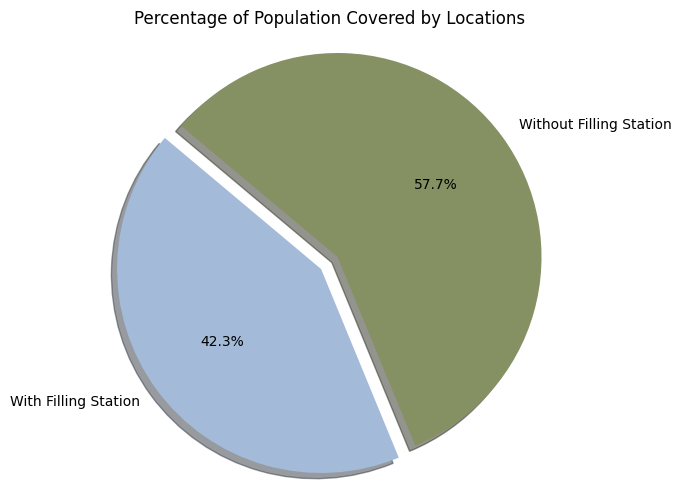

In [40]:
sum_density_for_non_inventory = total_avg_daily_density_cnt - sum_density_for_inventory

labels = 'With Filling Station', 'Without Filling Station'
sizes = [sum_density_for_inventory, sum_density_for_non_inventory]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Percentage of Population Covered by Locations')
plt.show()

# **Using Distance Data and Foot Traffic Data to find top 10 locations**

In [23]:
filtered_data = distance_data[distance_data['full_address'].isin(addresses_of_top_40)]

# Step 2: Sort the filtered DataFrame by 'distance_to_closest_station' in descending order to get the highest distances first
sorted_filtered_data = filtered_data.sort_values(by='distance_to_closest_station', ascending=False)

# Step 3: Select the top 20 from this sorted list
top_20_from_40 = sorted_filtered_data.head(20)

# Now 'top_20_from_40' contains the top 20 addresses with the highest distance_to_closest_station values among your specified 40 addresses
# If you need to display these addresses along with their distances:
print("Top 20 Addresses with the Highest Distance Values:")
print(top_20_from_40[['full_address', 'distance_to_closest_station']])

Top 20 Addresses with the Highest Distance Values:
                 full_address  distance_to_closest_station
233       264-270 bay state 1                   410.942694
3             163-179 amory 1                   384.444074
303       1010 commonwealth 1                   362.899718
415             278 babcock f                   317.533416
92         949 commonwealth 1                   290.970980
387    30 harry agganis way p                   283.140791
313                10 buick 3                   257.066757
307                10 buick 1                   257.066757
426  675 - 725 commonwealth b                   253.382323
715  675 - 725 commonwealth 2                   253.382323
805  675 - 725 commonwealth 3                   253.382323
232  745 - 755 commonwealth 1                   184.388122
418  722-26-28 commonwealth b                   148.394943
298  722-26-28 commonwealth 1                   148.394943
299  722-26-28 commonwealth 4                   148.394943
300  

In [24]:
top_20_addresses = [
    "264-270 bay state 1",
    "163-179 amory 1",
    "1010 commonwealth 1",
    "278 babcock f",
    "949 commonwealth 1",
    "30 harry agganis way p",
    "10 buick 3",
    "10 buick 1",
    "675 - 725 commonwealth b",
    "675 - 725 commonwealth 2",
    "675 - 725 commonwealth 3",
    "745 - 755 commonwealth 1",
    "722-26-28 commonwealth b",
    "722-26-28 commonwealth 1",
    "722-26-28 commonwealth 4",
    "722-26-28 commonwealth 2",
    "722-26-28 commonwealth 3",
    "722-26-28 commonwealth 5",
    "64-86 cummington mall b",
    "930-940 commonwealth 2"
]


filtered_density = daily_avg_density[daily_avg_density['full_address'].isin(top_20_addresses)]

sorted_filtered_density = filtered_density.sort_values(by='avg_daily_density_cnt', ascending=False)

top_10_density_from_top_20 = sorted_filtered_density.head(10)

print("Top 10 Addresses with Highest avg_daily_density_cnt from the Top 20 by Distance:")
print(top_10_density_from_top_20[['full_address', 'avg_daily_density_cnt']])

Top 10 Addresses with Highest avg_daily_density_cnt from the Top 20 by Distance:
                  full_address  avg_daily_density_cnt
51         1010 commonwealth 1            1266.999124
217            163-179 amory 1            1179.429907
529     30 harry agganis way p            1054.315189
1141        949 commonwealth 1             865.573181
893   722-26-28 commonwealth b             839.948899
887   722-26-28 commonwealth 2             792.228070
816    64-86 cummington mall b             780.725664
905   745 - 755 commonwealth 1             711.350661
9                   10 buick 1             702.048161
888   722-26-28 commonwealth 3             638.464912


In [25]:
sum_of_top_10_density = top_10_density_from_top_20['avg_daily_density_cnt'].sum()

total_sum_of_top_10_density = sum_of_top_10_density

print(f"Sum of the top 10 avg_daily_density_cnt values: {total_sum_of_top_10_density}")

Sum of the top 10 avg_daily_density_cnt values: 8831.083767832353


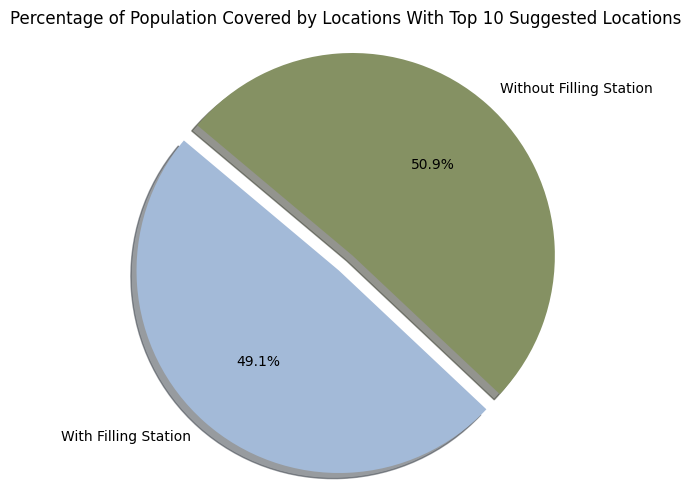

In [39]:
# if we were to install those 10 locations, how would the impact change?

sum_density_for_inventory_new = sum_density_for_inventory + total_sum_of_top_10_density

sum_density_for_non_inventory_new = total_avg_daily_density_cnt - sum_density_for_inventory_new

labels = 'With Filling Station', 'Without Filling Station'
sizes = [sum_density_for_inventory_new, sum_density_for_non_inventory_new]
colors = ['#a3bad8', '#859163']
explode = (0.1, 0)

# Plot
plt.figure(figsize=(8, 6))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)
plt.axis('equal')
plt.title('Percentage of Population Covered by Locations With Top 10 Suggested Locations')
plt.show()

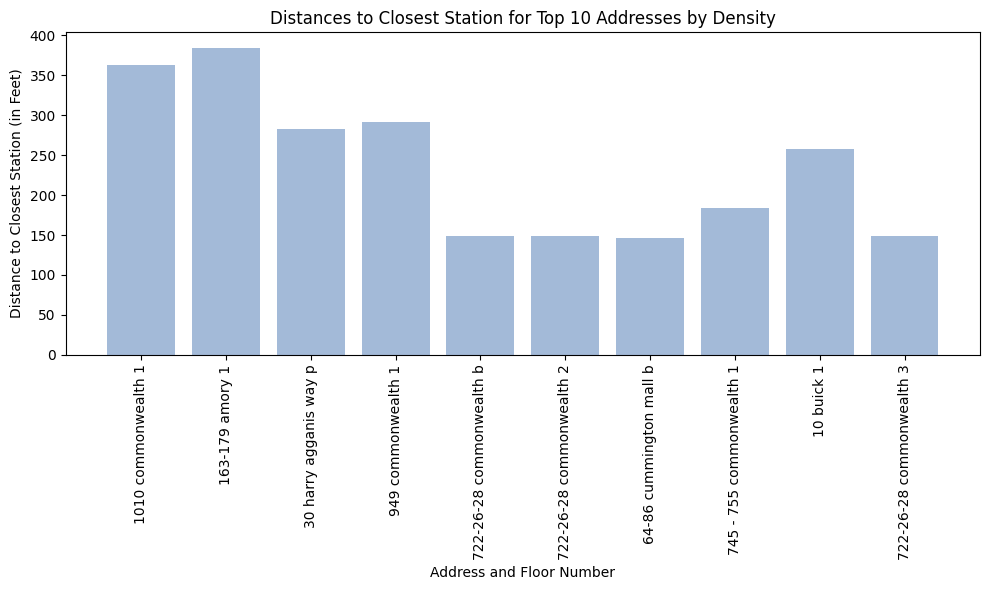

In [41]:
addresses_to_plot = top_10_density_from_top_20['full_address'].tolist()
filtered_distances = distance_data[distance_data['full_address'].isin(addresses_to_plot)]

filtered_distances_ordered = filtered_distances.set_index('full_address').reindex(index=addresses_to_plot).reset_index()

plt.figure(figsize=(10, 6))
plt.bar(filtered_distances_ordered['full_address'], filtered_distances_ordered['distance_to_closest_station'], color='#a3bad8')
plt.xlabel('Address and Floor Number')
plt.ylabel('Distance to Closest Station (in Feet)')
plt.title('Distances to Closest Station for Top 10 Addresses by Density')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# **Creating the data frame which will be used to get final prioritized list**

In [ ]:

# STILL WORKING ON THIS, NEED TO ADD THE MECHANICAL VENTILLATION FACTOR, AND THE MAINTENANCE FACTOR

final_outcome_df = pd.DataFrame(density_data_filtered['full_address'].unique(), columns=['full_address'])

final_outcome_df = pd.merge(final_outcome_df, address_distance_df[['full_address', 'max_distance_km']],
                            on='full_address', how='left')

final_outcome_df = pd.merge(final_outcome_df,
                            density_data_filtered[['full_address', 'avg_daily_density_cnt', 'exists_in_inventory']],
                            on='full_address',
                            how='left')

unique_building_types = density_data[['full_address', 'building_type']].drop_duplicates(subset=['full_address'], keep='first')

final_outcome_df = pd.merge(final_outcome_df, unique_building_types, on='full_address', how='left')


final_outcome_df.head()
print(final_outcome_df.shape)
